# Check for spikes in the altitude, wind, and pressure data
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

DELTA_ALT_THRESH = 25 # (m) the altitude spike threshold
DELTA_ALT_THRESH_JUMP = 50 # (m) the altitude jump threshold
DELTA_WIND_THRESH = 1/30 # (m/s**2) the wind spike threshold
DELTA_WIND_THRESH_JUMP = 1/60 # (m/s**2) the wind jump threshold
DELTA_P_THRESH = 1 # (hPa) the pressure spike threshold
DELTA_P_THRESH_JUMP = 2 # (hPa) the pressure jump threshold

In [7]:
# Load in the data
flights = pd.read_feather('Concordiasi_with_ERA5_3_data_gaps.feather')
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure,segment_id
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,8.44,-9.58,61.573,192.615719,0.000580,7.54,0
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,8.36,-9.75,61.616,192.613123,0.000580,7.70,0
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,8.37,-9.82,61.715,192.607186,0.000579,7.83,0
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,8.40,-9.79,61.751,192.605042,0.000579,7.97,0
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,8.43,-9.68,61.691,192.608620,0.000579,8.11,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2379058,19,2010-11-23 09:56:00,-76.331482,-20.582638,17357.0,10.34,6.53,66.633,207.918384,0.000660,11.57,167
2379059,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,10.33,6.50,66.584,207.932783,0.000660,11.60,167
2379060,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,10.30,6.47,66.571,207.936609,0.000660,11.62,167
2379061,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,10.28,6.44,66.583,207.933077,0.000660,11.63,167


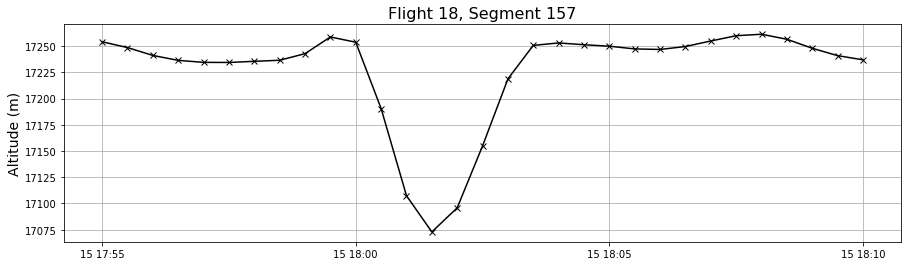

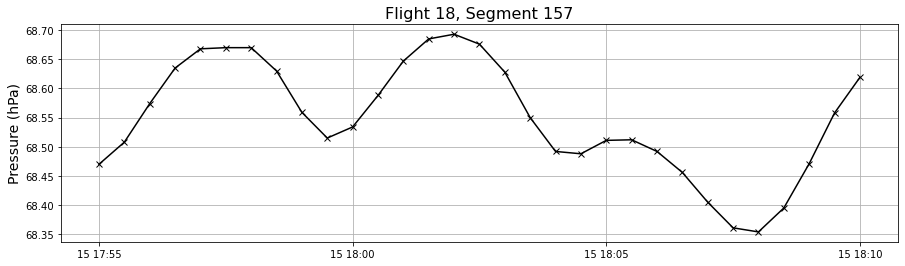

In [4]:
# Select a segment and zoom in on a specified time interval
segment_to_plot = 157

flight = flights[flights.segment_id == segment_to_plot]
#time_start = flight.time.iloc[0]
#time_stop = flight.time.iloc[-1]
time_start = pd.Timestamp('2010-11-15 17:55:00.00')
time_stop = pd.Timestamp('2010-11-15 18:10:00.00')
flight = flight[flight.time >= time_start]
flight = flight[flight.time <= time_stop]


plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.altitude,'-kx')
plt.grid()
plt.title(f'Flight {flight.flight_id.iloc[0]}, Segment {segment_to_plot}', fontsize=16)
plt.ylabel('Altitude (m)', fontsize=14);

plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.pressure,'-kx')
plt.grid()
plt.title(f'Flight {flight.flight_id.iloc[0]}, Segment {segment_to_plot}', fontsize=16)
plt.ylabel('Pressure (hPa)', fontsize=14);

In [10]:
# Mark altitude spikes in the data
# These are spikes in the altitude data that are not concurrent with consistent changes in the pressure data
flights['spike_altitude'] = 0


# Flight 01
print('Flight 01 number of data points in spike:')
temp = flights[flights.spike_altitude == 1].shape[0]
flights.loc[(flights.flight_id == '01') & 
            (flights.time >= pd.Timestamp('2010-10-25 10:20:45.00')) &
            (flights.time <= pd.Timestamp('2010-10-25 10:22:15.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 02
print('Flight 02 number of data points in spike:')
flights.loc[(flights.flight_id == '02') & 
            (flights.time >= pd.Timestamp('2010-10-01 03:36:15.00')) &
            (flights.time <= pd.Timestamp('2010-10-01 03:41:45.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
flights.loc[(flights.flight_id == '02') & 
            (flights.time >= pd.Timestamp('2010-10-03 02:04:15.00')) &
            (flights.time <= pd.Timestamp('2010-10-03 02:12:15.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 04
print('Flight 04 number of data points in spike:')
flights.loc[(flights.flight_id == '04') & 
            (flights.time >= pd.Timestamp('2010-10-23 00:30:45.00')) &
            (flights.time <= pd.Timestamp('2010-10-23 00:43:15.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 06
print('Flight 06 number of data points in spike:')
flights.loc[(flights.flight_id == '06') & 
            (flights.time >= pd.Timestamp('2010-10-20 17:58:15.00')) &
            (flights.time <= pd.Timestamp('2010-10-20 18:01:45.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 07
print('Flight 07 number of data points in spike:')
flights.loc[(flights.flight_id == '07') & 
            (flights.time >= pd.Timestamp('2010-11-22 08:08:45.00')) &
            (flights.time <= pd.Timestamp('2010-11-22 08:12:15.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 11
print('Flight 11 number of data points in spike:')
flights.loc[(flights.flight_id == '11') & 
            (flights.time >= pd.Timestamp('2010-10-19 20:44:15.00')) &
            (flights.time <= pd.Timestamp('2010-10-19 20:46:45.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

# Flight 18
print('Flight 18 number of data points in spike:')
flights.loc[(flights.flight_id == '18') & 
            (flights.time >= pd.Timestamp('2010-11-15 17:59:45.00')) &
            (flights.time <= pd.Timestamp('2010-11-15 18:03:45.00')), 'spike_altitude'] = 1
print(flights[flights.spike_altitude == 1].shape[0] - temp)
temp = flights[flights.spike_altitude == 1].shape[0]
print()

Flight 01 number of data points in spike:
3

Flight 02 number of data points in spike:
11
16

Flight 04 number of data points in spike:
25

Flight 06 number of data points in spike:
7

Flight 07 number of data points in spike:
7

Flight 11 number of data points in spike:
5

Flight 18 number of data points in spike:
8



In [15]:
# Set the data where there are altitude spike to NaN, so they are interpolated over later

flights.loc[flights.spike_altitude == 1, ['altitude']] = np.nan

# Delete all the flags that I've made
flights = flights.drop(columns = ['spike_altitude','altitude_spike','altitude_jump',
                                  'wind_spike_u','wind_jump_u',
                                  'wind_spike_v','wind_jump_v',
                                  'pressure_spike','pressure_jump',
                                  'dt'])

# Save the data
flights.to_feather('Concordiasi_with_ERA5_4_spikes.feather') 
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure,segment_id
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,8.44,-9.58,61.573,192.615719,0.000580,7.54,0
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,8.36,-9.75,61.616,192.613123,0.000580,7.70,0
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,8.37,-9.82,61.715,192.607186,0.000579,7.83,0
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,8.40,-9.79,61.751,192.605042,0.000579,7.97,0
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,8.43,-9.68,61.691,192.608620,0.000579,8.11,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2379058,19,2010-11-23 09:56:00,-76.331482,-20.582638,17357.0,10.34,6.53,66.633,207.918384,0.000660,11.57,167
2379059,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,10.33,6.50,66.584,207.932783,0.000660,11.60,167
2379060,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,10.30,6.47,66.571,207.936609,0.000660,11.62,167
2379061,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,10.28,6.44,66.583,207.933077,0.000660,11.63,167
